# **Лабораторная 1. Иерархический кластерный анализ**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Провести пошаговую кластеризацию набора данных
2. Проанализировать методом иерархической кластеризации набор ruspini

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

## 1.1. Пошаговая кластеризация набора данных

### Данные *(Вариант 16)*

In [2]:
data = pd.DataFrame({'X1': [19, 21, 34, 17], 'X2': [31, 33, 60, 37]}, index=[1, 2, 3, 4])
data.columns.name = 'Объект'
data

Объект,X1,X2
1,19,31
2,21,33
3,34,60
4,17,37


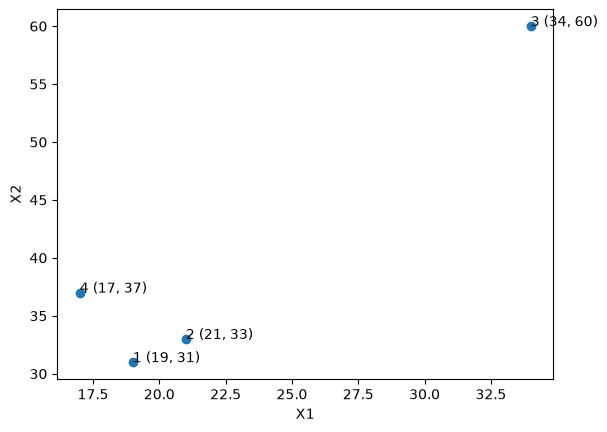

In [3]:
plt.scatter(data['X1'], data['X2'])
for i in data.index:
    plt.text(data['X1'][i], data['X2'][i], f"{i} ({data['X1'][i]}, {data['X2'][i]})")
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

### Метрика расстояния

Использую евклидово расстояние как стандартную метрику: в данных нет особенностей, требующих другой меры. Сильных отличий по отдельному признаку нет, а выбранный метод объединения не требует квадратов.
$$d(i, j) = \sqrt{(X1_i - X1_j)^2 + (X2_i - X2_j)^2}$$

In [4]:
def euclid(i, j):
    return np.sqrt((data['X1'][i] - data['X1'][j])**2 + (data['X2'][i] - data['X2'][j])**2)

### Метод объединения объектов в кластеры

Беру метод ближайшего соседа, где расстояние между кластерами равно расстоянию между их самыми близкими объектами. Группы на графике чётко разделены, поэтому выбор метода на разбиение не влияет, а этот метод проще всего для пошагового расчёта.
$$D(A, B) = \min_{i \in A,\ j \in B} d(i, j)$$

In [5]:
def cluster_dist(A, B):
    return min(euclid(i, j) for i in A for j in B)

### Пошаговая кластеризация

In [6]:
clusters = [[i] for i in data.index]
ids = list(range(len(data)))
merges = []
step = 1
print(clusters)
while len(clusters) > 1:
    min_dist = None
    for a in range(len(clusters)):
        for b in range(a + 1, len(clusters)):
            d = cluster_dist(clusters[a], clusters[b])
            if min_dist is None or d < min_dist[0]:
                min_dist = [d, a, b]
    d, a, b = min_dist
    print(f'Шаг: {step}. Объединяются {clusters[a]} и {clusters[b]} с расстоянием {d:.2f}')
    new_cluster = clusters[a] + clusters[b]
    merges.append([ids[a], ids[b], d, len(new_cluster)])
    del clusters[b], clusters[a]
    del ids[b], ids[a]
    clusters.append(new_cluster)
    ids.append(len(data) + len(merges) - 1)
    print(clusters)
    step += 1

[[1], [2], [3], [4]]
Шаг: 1. Объединяются [1] и [2] с расстоянием 2.83
[[3], [4], [1, 2]]
Шаг: 2. Объединяются [4] и [1, 2] с расстоянием 5.66
[[3], [4, 1, 2]]
Шаг: 3. Объединяются [3] и [4, 1, 2] с расстоянием 28.60
[[3, 4, 1, 2]]


### Дендрограмма

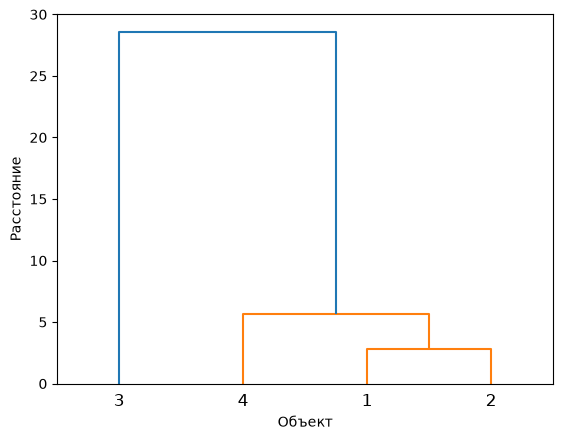

In [7]:
dendrogram(np.array(merges), labels=[str(i) for i in data.index])
plt.xlabel('Объект')
plt.ylabel('Расстояние')
plt.show()

### Результат

Объекты 1, 2 и 4 близки друг к другу и объединяются на расстояниях 2.83 и 5.66, объект 3 присоединяется только на 28.60. Самый большой скачок расстояния — на последнем шаге, поэтому данные делятся на 2 кластера: {1, 2, 4} и {3}.

## 1.2. Иерархическая кластеризация набора ruspini

### Данные

Набор ruspini из R-пакета cluster: 75 точек с двумя признаками x и y.

In [8]:
ruspini = pd.read_csv('https://vincentarelbundock.github.io/Rdatasets/csv/cluster/ruspini.csv', index_col=0)
ruspini

,x,y
rownames,,
1,4,53
2,5,63
3,10,59
4,9,77
5,13,49
...,...,...
71,66,23
72,61,25
73,76,27


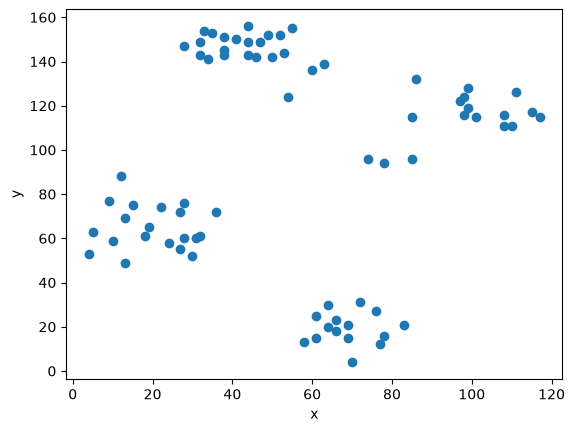

In [9]:
plt.scatter(ruspini['x'], ruspini['y'])
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Сравнение методов объединения

На графике 4 компактные группы, но часть точек лежит между ними. Куда они попадут, зависит от метода объединения, поэтому строю иерархию всеми шестью методами и сравниваю результаты.

Метрика везде евклидова. Центроидному, медианному и методу Уорда нужен квадрат евклидовой, scipy возводит расстояния в квадрат сам.

In [10]:
methods = {'single': 'Ближайший сосед', 'complete': 'Дальний сосед', 'average': 'Групповое среднее',
           'centroid': 'Центроидный', 'median': 'Медианный', 'ward': 'Уорда'}
X = ruspini[['x', 'y']]
results = {}
for method in methods:
    results[method] = linkage(X, method=method)

### Дендрограммы

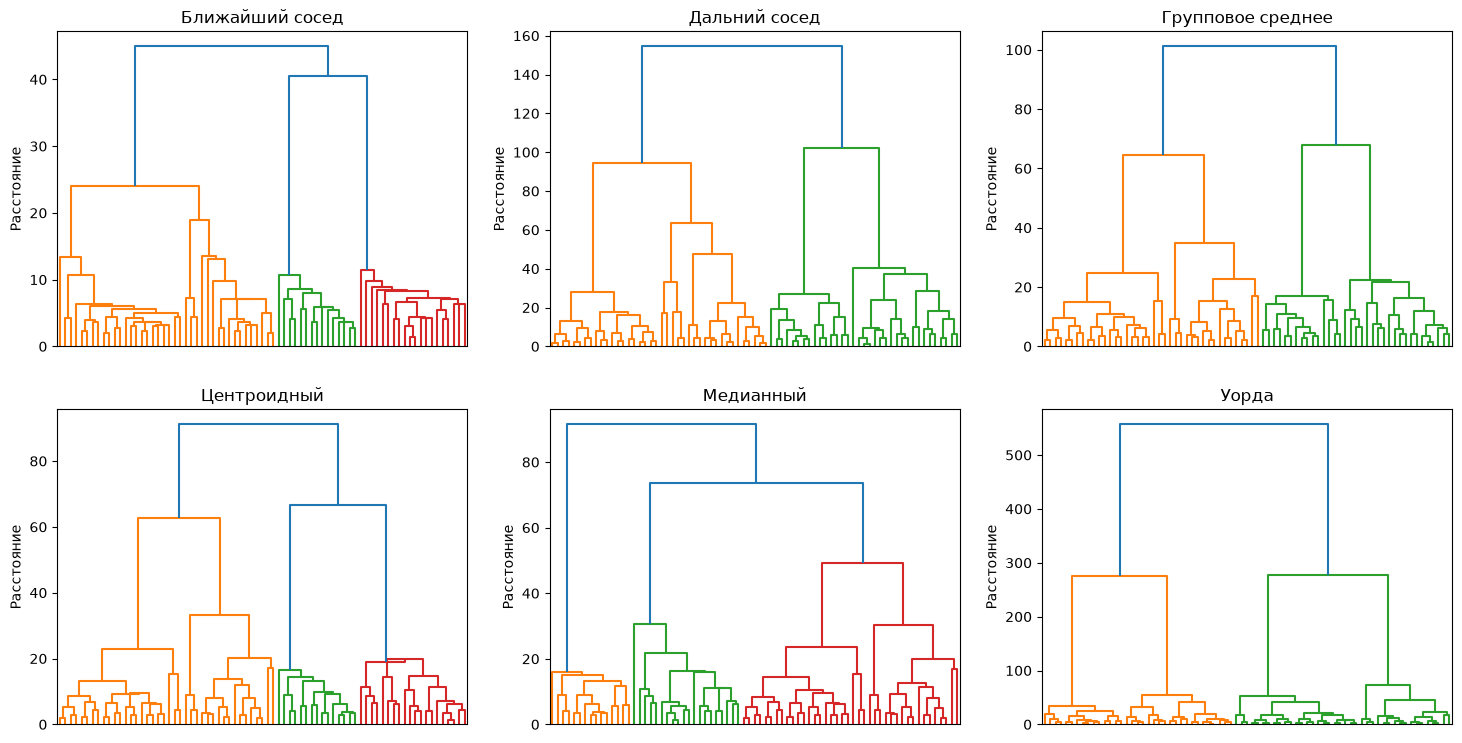

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, method in zip(axes.flat, methods):
    dendrogram(results[method], ax=ax, no_labels=True)
    ax.set_title(methods[method])
    ax.set_ylabel('Расстояние')
plt.show()

### Выбор числа кластеров

Визуально проанализировав дендрограммы, точку отсечения выбираю на уровне 4 кластеров: верхние слияния делят дерево на 4 крупные ветви, а внутри них объекты объединяются на заметно меньшей высоте. Это совпадает с 4 группами точек на диаграмме рассеяния.

### Разбиение на 4 кластера

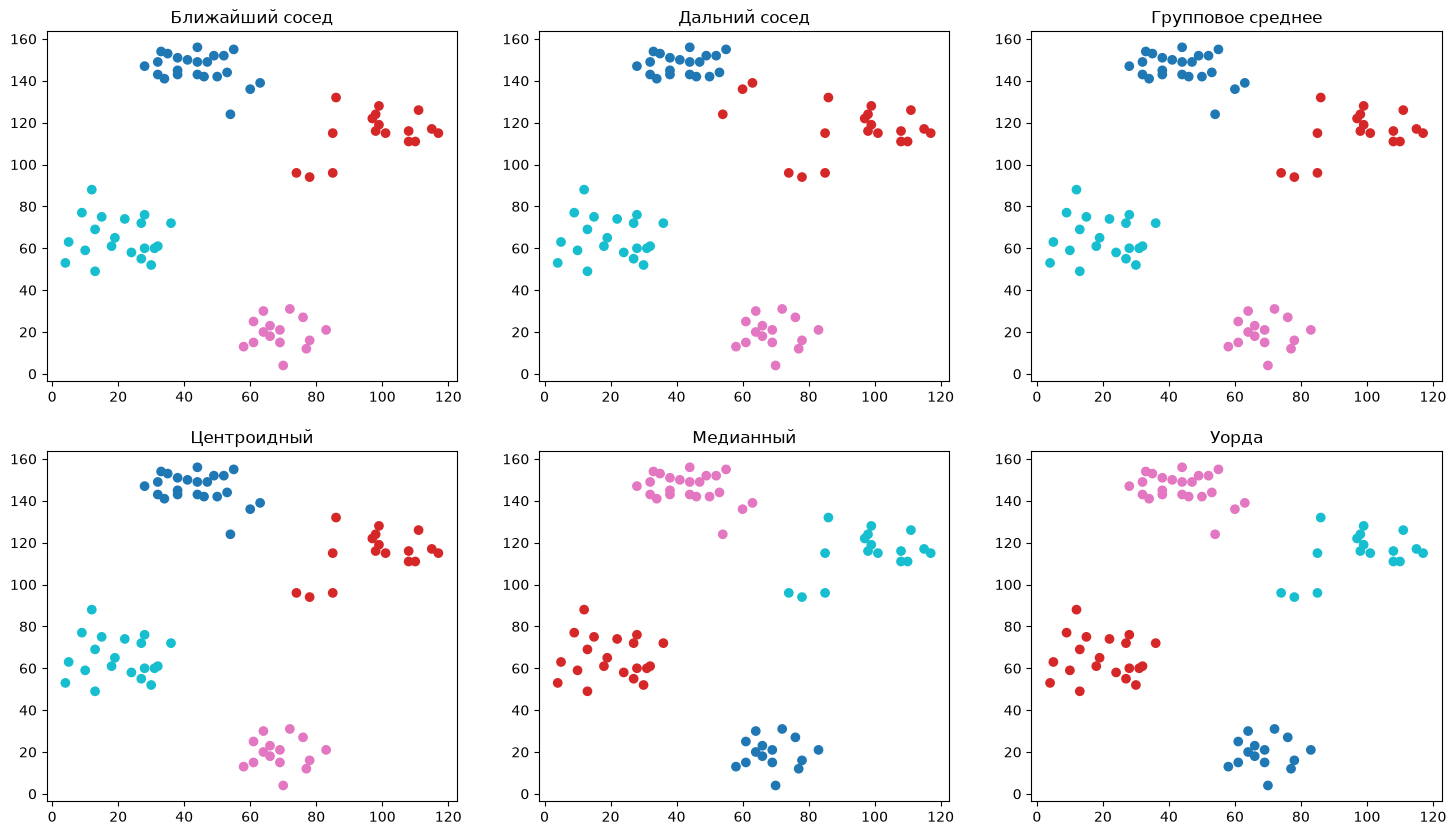

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, method in zip(axes.flat, methods):
    labels = fcluster(results[method], 4, criterion='maxclust')
    ax.scatter(X['x'], X['y'], c=labels, cmap='tab10')
    ax.set_title(methods[method])
plt.show()

### Анализ методов

- **Ближайший сосед** — разбиение совпадает с видимыми группами, но группы на дендрограмме отделены слабо. Расстояние между кластерами берётся по самым близким точкам, а промежуточные точки его сокращают, поэтому группы сливаются почти на той же высоте, что и точки внутри них — цепочечный эффект.
- **Дальний сосед** — три точки почти сверху посередине попали в правый кластер. Расстояние до кластера считается по самой далёкой точке, а верхняя группа широкая: до её левого края от этих точек дальше, чем до точек правой группы. Поэтому они раньше слились с этими точками и вместе с ними ушли в правый кластер. Слияния необратимы, и на следующих шагах это уже не исправляется.
- **Групповое среднее** — разбиение совпадает с видимыми группами. Среднее всех попарных расстояний меньше зависит от одной далёкой точки, чем максимум, и от одной близкой, чем минимум.
- **Центроидный и медианный** — разбиение совпадает с видимыми группами, но эти методы допускают инверсии: после слияния центр сдвигается и может оказаться ближе к соседнему кластеру, поэтому следующее слияние бывает ниже предыдущего.
- **Уорда** — разбиение совпадает с видимыми группами, а 4 ветви на дендрограмме самые длинные. Метод сливает кластеры с наименьшим приростом суммы квадратов отклонений, то есть ищет компактные группы близкого размера, а на графике как раз такие.

Итоговое разбиение строю методом Уорда: промежуточные точки отнесены к своим группам, а 4 кластера на дендрограмме видны лучше всего.

### Итоговое разбиение методом Уорда

Режу дерево на 4 кластера: линия на высоте 150 пересекает 4 ветви. Кластеры выделяю цветом на дендрограмме и на диаграмме рассеяния.

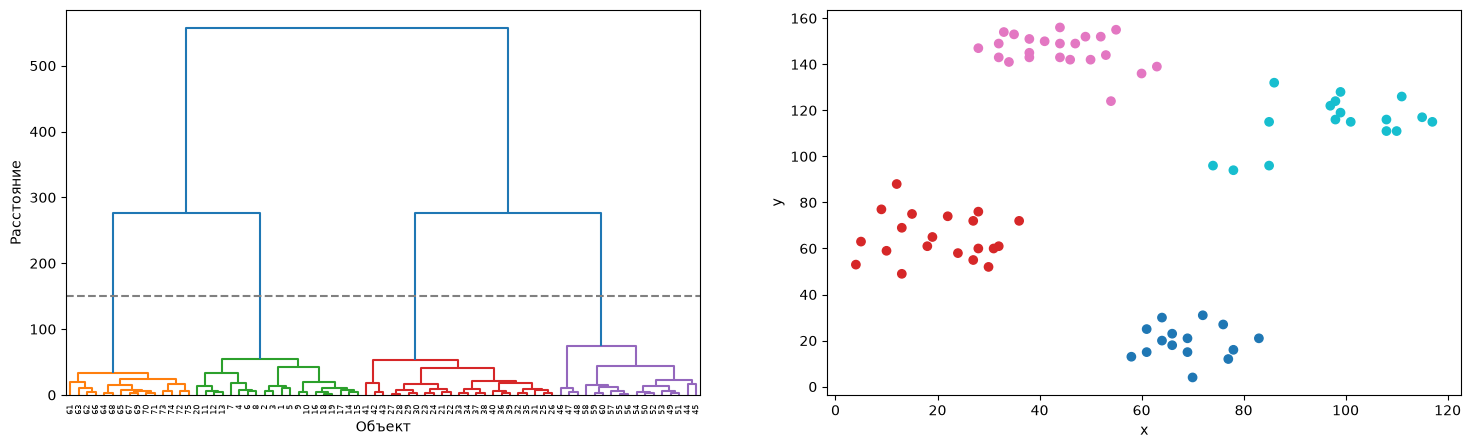

cluster
1    15
2    20
3    23
4    17
Name: count, dtype: int64

In [13]:
merges = results['ward']
ruspini['cluster'] = fcluster(merges, 4, criterion='maxclust')

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
dendrogram(merges, ax=axes[0], labels=list(ruspini.index), color_threshold=150)
axes[0].axhline(150, color='gray', linestyle='--')
axes[0].set_xlabel('Объект')
axes[0].set_ylabel('Расстояние')
axes[1].scatter(ruspini['x'], ruspini['y'], c=ruspini['cluster'], cmap='tab10')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
plt.show()

ruspini['cluster'].value_counts().sort_index()

### Работа с отдельными кластерами

Объекты кластера 1:

In [14]:
ruspini[ruspini['cluster'] == 1]

,x,y,cluster
rownames,,,
61,70,4,1
62,77,12,1
63,83,21,1
64,61,15,1
65,69,15,1
66,78,16,1
67,66,18,1
68,58,13,1
69,64,20,1


Статистики внутри кластеров:

In [15]:
ruspini.groupby('cluster')[['x', 'y']].agg(['mean', 'median', 'min', 'max'])

x                           y                 
              mean median min  max        mean median  min  max
cluster                                                        
1        68.933333   69.0  58   83   19.400000   20.0    4   31
2        20.150000   20.5   4   36   64.950000   62.0   49   88
3        43.913043   44.0  28   63  146.043478  147.0  124  156
4        98.176471   99.0  74  117  114.882353  116.0   94  132

## Вывод

В пункте 1.1 пошаговая кластеризация методом ближайшего соседа разделила 4 объекта на 2 кластера: {1, 2, 4} и {3}.

В пункте 1.2 иерархия набора ruspini построена всеми шестью методами объединения. Число кластеров выбрано визуально по дендрограммам: 4 крупные ветви, что совпадает с 4 группами на диаграмме рассеяния. Пять методов отнесли промежуточные точки к их группам. Дальний сосед отнёс 3 точки верхней группы к правой, т.к. сравнивает кластеры по самым далёким точкам, а верхняя группа широкая. У ближнего соседа группы на дендрограмме разделены слабее всего из-за промежуточных точек, центроидный и медианный допускают инверсии.

Итоговое разбиение построено методом Уорда: на его дендрограмме 4 кластера видны лучше всего. Получились кластеры из 15, 20, 23 и 17 объектов, они совпадают с видимыми группами точек. Самый разреженный — кластер 4: x от 74 до 117, y от 94 до 132, в него попали точки слева от правой группы.